<>:180: SyntaxWarning: invalid escape sequence '\c'
<>:180: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1003/3085732118.py:180: SyntaxWarning: invalid escape sequence '\c'
  ax.text(crit, -0.024, "$\chi^2$ crítico", color='#FFFFFF', fontsize=9, ha='center', va='top')


Generando animación 3x4 corregida a 20 FPS...


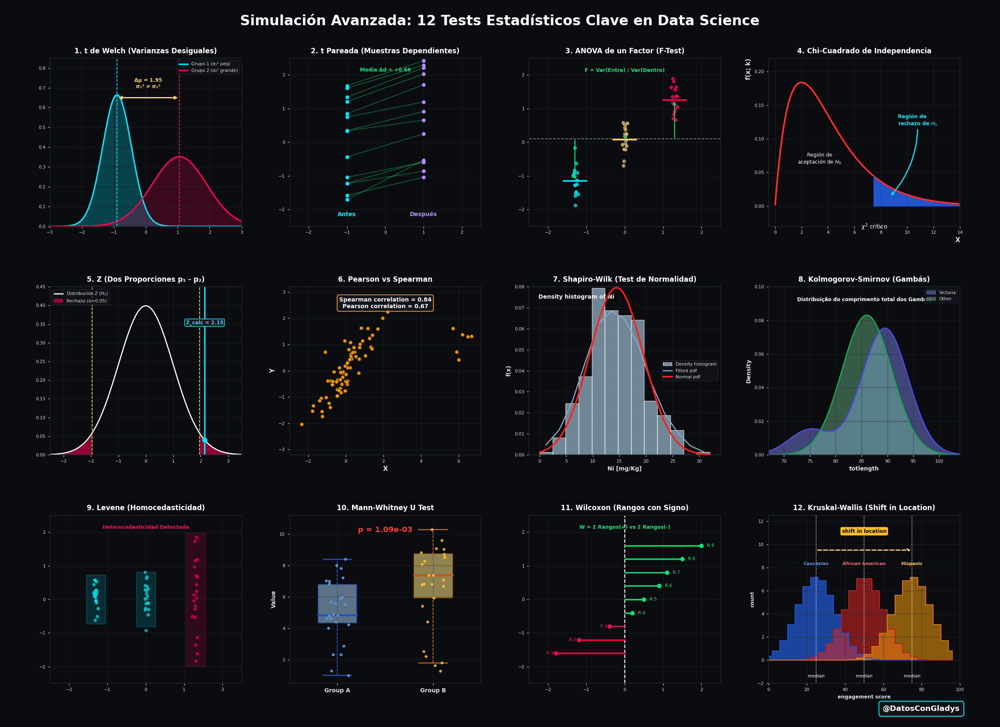

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import matplotlib.patches as patches
from scipy.stats import norm, chi2
from scipy.ndimage import gaussian_filter1d
from IPython.display import Image, display

# ==========================================
# 1. CONFIGURACIÓN ESTÉTICA (DARK NEON PREMIUM)
# ==========================================
BG_COLOR = '#0B0C10'
GRID_COLOR = '#1F2833'
TEXT_COLOR = '#E0E0E0'

COLOR_CYAN = '#00E5FF'
COLOR_MAGENTA = '#FF0055'
COLOR_GREEN = '#00E676'
COLOR_YELLOW = '#FFD166'
COLOR_ORANGE = '#FF9100'
COLOR_PURPLE = '#B388FF'

fig, axs = plt.subplots(3, 4, figsize=(22, 16), facecolor=BG_COLOR)
fig.suptitle("Simulación Avanzada: 12 Tests Estadísticos Clave en Data Science",
             fontsize=22, color='#FFFFFF', fontweight='bold', y=0.98)
plt.subplots_adjust(hspace=0.36, wspace=0.25, top=0.92, bottom=0.06, left=0.05, right=0.96)

FRAMES = 60

def style_ax(ax, title):
    ax.set_facecolor(BG_COLOR)
    ax.grid(True, color=GRID_COLOR, linestyle='-', linewidth=0.8, alpha=0.6)
    ax.set_title(title, fontsize=11, color='#FFFFFF', fontweight='bold', pad=8)
    ax.tick_params(colors=TEXT_COLOR, labelsize=7)
    for spine in ax.spines.values():
        spine.set_color(GRID_COLOR)
        spine.set_linewidth(1.0)

# ==========================================
# 2. GENERACIÓN DE DATOS BASE FIJOS
# ==========================================
np.random.seed(42)

# 2. t Pareada
paired_before = np.random.uniform(-1.8, 1.8, 14)
paired_diffs = np.random.normal(0.8, 0.25, 14)
paired_after = paired_before + paired_diffs

# 3. ANOVA
anova_g1 = np.random.normal(-1.0, 0.45, 16)
anova_g2 = np.random.normal(0.1, 0.45, 16)
anova_g3 = np.random.normal(1.2, 0.45, 16)

# 6. Pearson & Spearman (Foto 2)
n_main = 70
x_main = np.random.normal(0, 0.9, n_main)
y_main = 0.92 * x_main + np.random.normal(0, 0.45, n_main)
x_out = np.array([5.7, 6.0, 6.2, 6.5, 5.9, 6.7])
y_out = np.array([1.6, 0.4, 1.4, 1.3, 0.7, 1.3])
x_corr = np.concatenate([x_main, x_out])
y_corr = np.concatenate([y_main, y_out])

# 7. Shapiro-Wilk (Foto 3 - Ni dataset)
data_ni = np.random.normal(14.5, 5.2, 350)
data_ni = data_ni[(data_ni >= 0) & (data_ni <= 33)]

# 8. Kolmogorov-Smirnov (Foto 4 - Gambas)
x_gambas = np.linspace(67, 104, 200)
pdf_vic = 0.85 * norm.pdf(x_gambas, 89.5, 4.5) + 0.15 * norm.pdf(x_gambas, 75, 4.0)
pdf_oth = norm.pdf(x_gambas, 86.0, 4.8)

# 10. Mann-Whitney U (Foto 5)
pts_mwu_a = np.array([1.0, 1.3, 2.3, 2.3, 2.9, 4.0, 4.2, 4.4, 4.6, 4.6, 4.8, 4.8, 4.9, 5.5, 5.6, 5.7, 5.9, 6.0, 6.8, 7.0, 7.0, 7.2, 7.8, 8.0, 8.4])
pts_mwu_b = np.array([1.3, 1.6, 1.8, 2.2, 2.5, 4.4, 5.4, 5.9, 6.7, 6.8, 6.8, 6.8, 7.1, 7.4, 7.4, 8.1, 8.3, 8.5, 8.7, 8.8, 9.0, 9.1, 9.6, 10.3])

# 12. Kruskal-Wallis (Foto 6 - 3 grupos escalonados)
bins_kw = np.linspace(0, 100, 26)

# Fases fijas para micro-jitter local
phase_paired = np.random.uniform(0, 2*np.pi, len(paired_before))
phase_corr = np.random.uniform(0, 2*np.pi, len(x_corr))
phase_mwu_a = np.random.uniform(0, 2*np.pi, len(pts_mwu_a))
phase_mwu_b = np.random.uniform(0, 2*np.pi, len(pts_mwu_b))

# ==========================================
# 3. FUNCIONES DE DIBUJO POR PANEL
# ==========================================

# 1. t de Welch (Curvas en movimiento continuo)
def draw_welch(ax, t):
    style_ax(ax, "1. t de Welch (Varianzas Desiguales)")
    shift1 = 0.15 * np.sin(t)
    shift2 = 0.15 * np.cos(t)
    x = np.linspace(-3.0, 3.0, 200)

    pdf1 = norm.pdf(x, -0.9 + shift1, 0.45) * 0.75
    pdf2 = norm.pdf(x, 0.9 + shift2, 0.85) * 0.75

    ax.plot(x, pdf1, color=COLOR_CYAN, lw=2.2, label='Grupo 1 (σ₁² peq)')
    ax.plot(x, pdf2, color=COLOR_MAGENTA, lw=2.2, label='Grupo 2 (σ₂² grande)')
    ax.fill_between(x, pdf1, color=COLOR_CYAN, alpha=0.25)
    ax.fill_between(x, pdf2, color=COLOR_MAGENTA, alpha=0.20)

    m1, m2 = -0.9 + shift1, 0.9 + shift2
    ax.axvline(m1, color=COLOR_CYAN, lw=1.2, ls='--')
    ax.axvline(m2, color=COLOR_MAGENTA, lw=1.2, ls='--')
    ax.annotate('', xy=(m2, 0.65), xytext=(m1, 0.65),
                arrowprops=dict(arrowstyle="<->", color=COLOR_YELLOW, lw=2.0))
    ax.text((m1+m2)/2, 0.70, f"Δμ = {abs(m2-m1):.2f}\nσ₁² ≠ σ₂²", color=COLOR_YELLOW, fontsize=8, ha='center', fontweight='bold')
    ax.set_xlim(-3.0, 3.0)
    ax.set_ylim(0, 0.85)
    ax.legend(loc='upper right', facecolor='#12141A', edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR, fontsize=7)

# 2. t Pareada (Mantenida intacta)
def draw_paired_t(ax, t):
    style_ax(ax, "2. t Pareada (Muestras Dependientes)")
    j = 0.02 * np.sin(t + phase_paired)
    x_before, x_after = -1.0, 1.0
    pulse_alpha = 0.4 + 0.3 * np.sin(t*3)**2

    for b, a, jit in zip(paired_before, paired_after, j):
        y_b, y_a = b + jit, a + jit
        col = COLOR_GREEN if (y_a - y_b) > 0 else COLOR_MAGENTA
        ax.plot([x_before, x_after], [y_b, y_a], color=col, lw=1.2, alpha=pulse_alpha)
        ax.scatter([x_before], [y_b], color=COLOR_CYAN, s=25, zorder=4)
        ax.scatter([x_after], [y_a], color=COLOR_PURPLE, s=25, zorder=4)

    ax.text(x_before, -2.2, "Antes", color=COLOR_CYAN, fontsize=9, ha='center', fontweight='bold')
    ax.text(x_after, -2.2, "Después", color=COLOR_PURPLE, fontsize=9, ha='center', fontweight='bold')
    ax.text(0, 2.1, f"Media Δd = +{np.mean(paired_diffs):.2f}", color=COLOR_GREEN, fontsize=8, ha='center', fontweight='bold')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)

# 3. ANOVA de un Factor (Mantenida intacta)
def draw_anova(ax, t):
    style_ax(ax, "3. ANOVA de un Factor (F-Test)")
    xs = [-1.3, 0.0, 1.3]
    groups = [anova_g1, anova_g2, anova_g3]
    colors = [COLOR_CYAN, COLOR_YELLOW, COLOR_MAGENTA]

    grand_mean = 0.1
    ax.axhline(grand_mean, color='#FFFFFF', lw=1.2, ls='--', alpha=0.5)
    pulse = 0.05 * np.sin(t*3)

    for x_pos, grp, col in zip(xs, groups, colors):
        m = np.mean(grp) + pulse
        ax.scatter(np.full_like(grp, x_pos) + np.random.normal(0, 0.04, len(grp)), grp, color=col, s=22, alpha=0.7)
        ax.plot([x_pos - 0.3, x_pos + 0.3], [m, m], color=col, lw=2.5)
        ax.annotate('', xy=(x_pos, m), xytext=(x_pos, grand_mean),
                    arrowprops=dict(arrowstyle="->", color=COLOR_GREEN, lw=1.5))

    ax.text(0, 2.1, "F = Var(Entre) / Var(Dentro)", color=COLOR_GREEN, fontsize=8, ha='center', fontweight='bold')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)

# 4. Chi-Cuadrado de Independencia
def draw_chisquare(ax, t):
    style_ax(ax, "4. Chi-Cuadrado de Independencia")
    x = np.linspace(0.01, 14, 250)
    k_df = 4.0 + 0.25 * np.sin(t)
    pdf = chi2.pdf(x, df=k_df)
    crit = 7.5

    # Curva Chi-cuadrado roja de la foto
    ax.plot(x, pdf, color='#FF2A2A', lw=2.6)

    # Región de rechazo sombreada en azul
    mask_rej = x >= crit
    ax.fill_between(x[mask_rej], pdf[mask_rej], color='#2563EB', alpha=0.85)
    ax.plot([crit, crit], [0, chi2.pdf(crit, df=k_df)], color='#2563EB', lw=2.0)

    # Textos de aceptación y flecha de rechazo
    ax.text(crit * 0.45, 0.07, "Región de\naceptación de $H_0$", color='#FFFFFF', fontsize=8, ha='center', va='center')
    ax.annotate("Región de\nrechazo de $H_0$",
                xy=(crit + 1.2, chi2.pdf(crit + 1.2, df=k_df)/2),
                xytext=(crit + 1.8, 0.12),
                arrowprops=dict(arrowstyle="->", color='#00E5FF', lw=1.8, connectionstyle="arc3,rad=-0.2"),
                color='#00E5FF', fontsize=8, fontweight='bold', ha='left')

    ax.text(crit, -0.024, "$\chi^2$ crítico", color='#FFFFFF', fontsize=9, ha='center', va='top')
    ax.set_xlabel("X", color=TEXT_COLOR, fontsize=10, fontweight='bold', loc='right')
    ax.set_ylabel("f(x; k)", color=TEXT_COLOR, fontsize=10, fontweight='bold', loc='top')
    ax.set_xlim(-0.5, 14)
    ax.set_ylim(-0.03, 0.22)

# 5. Z para Dos Proporciones
def draw_z_two_props(ax, t):
    style_ax(ax, "5. Z (Dos Proporciones p₁ - p₂)")
    x = np.linspace(-3.5, 3.5, 250)
    pdf_null = norm.pdf(x, 0, 1.0)
    z_obs = 2.15 + 0.25 * np.sin(t)

    # Curva normal estándar bajo H0
    ax.plot(x, pdf_null, color='#FFFFFF', lw=1.8, label='Distribución Z ($H_0$)')
    ax.fill_between(x[x >= 1.96], pdf_null[x >= 1.96], color=COLOR_MAGENTA, alpha=0.55, label='Rechazo (α=0.05)')
    ax.fill_between(x[x <= -1.96], pdf_null[x <= -1.96], color=COLOR_MAGENTA, alpha=0.55)
    ax.axvline(1.96, color=COLOR_YELLOW, lw=1.2, ls='--')
    ax.axvline(-1.96, color=COLOR_YELLOW, lw=1.2, ls='--')

    # Marcador de Z observado
    ax.axvline(z_obs, color=COLOR_CYAN, lw=2.2)
    ax.scatter([z_obs], [norm.pdf(z_obs, 0, 1.0)], color=COLOR_CYAN, s=50, zorder=5)
    ax.text(z_obs, 0.35, f"Z_calc = {z_obs:.2f}", color=COLOR_CYAN, fontsize=8, ha='center', fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.2", facecolor='#12141A', edgecolor=COLOR_CYAN, lw=1.0))

    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(0, 0.45)
    ax.legend(loc='upper left', facecolor='#12141A', edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR, fontsize=7)

# 6. Correlación de Pearson y Spearman
def draw_pearson_spearman(ax, t):
    style_ax(ax, "6. Pearson vs Spearman")
    j = 0.025 * np.sin(t + phase_corr)

    # Dispersión con puntos atípicos de apalancamiento
    ax.scatter(x_corr, y_corr + j, facecolor='#FFA500', edgecolor='#3E1F00', s=35, linewidth=0.8, alpha=0.9, zorder=4)
    ax.text(0.5, 0.94, "Spearman correlation = 0.84\nPearson correlation = 0.67",
            transform=ax.transAxes, color='#FFFFFF', fontsize=9, ha='center', va='top', fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.35", facecolor='#12141A', edgecolor='#FFA500', lw=1.2))

    ax.set_xlabel("X", color=TEXT_COLOR, fontsize=10, fontweight='bold')
    ax.set_ylabel("Y", color=TEXT_COLOR, fontsize=10, fontweight='bold')
    ax.set_xlim(-3.0, 7.2)
    ax.set_ylim(-3.2, 3.2)

# 7. Shapiro-Wilk
def draw_shapiro(ax, t):
    style_ax(ax, "7. Shapiro-Wilk (Test de Normalidad)")

    # Histograma de Ni
    bins = np.linspace(0, 32, 14)
    counts, edges, _ = ax.hist(data_ni, bins=bins, density=True,
                               facecolor='#A6C8E0', edgecolor='#FFFFFF', alpha=0.65,
                               linewidth=1.0, label='Density histogram', zorder=2)

    # Línea de densidad empírica ajustada
    centers = (edges[:-1] + edges[1:]) / 2
    smooth_y = gaussian_filter1d(counts, sigma=1.0) + 0.001 * np.sin(t)
    ax.plot(centers, smooth_y, color='#8CA6BD', lw=1.8, label='Fitted pdf', zorder=3)

    # Campana normal teórica roja
    x_range = np.linspace(0, 32, 150)
    mu, std = np.mean(data_ni), np.std(data_ni)
    pdf_norm = norm.pdf(x_range, mu, std)
    ax.plot(x_range, pdf_norm, color='#FF1A1A', lw=2.5, label='Normal pdf', zorder=4)

    ax.text(0.05, 0.93, "Density histogram of Ni", transform=ax.transAxes,
            color='#FFFFFF', fontsize=9, fontweight='bold')
    ax.set_xlabel("Ni [mg/Kg]", color=TEXT_COLOR, fontsize=9, fontweight='bold')
    ax.set_ylabel("f(x)", color=TEXT_COLOR, fontsize=9, fontweight='bold')
    ax.set_xlim(-2, 34)
    ax.set_ylim(0, 0.08)
    ax.legend(loc='center right', facecolor='#12141A', edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR, fontsize=7)

# 8. Kolmogorov-Smirnov
def draw_ks_gambas(ax, t):
    style_ax(ax, "8. Kolmogorov-Smirnov (Gambás)")
    pulse = 0.002 * np.sin(t*3)

    # Curva Victoria (Azul/Violeta)
    ax.plot(x_gambas, pdf_vic + pulse, color='#4F46E5', lw=2.0)
    ax.fill_between(x_gambas, pdf_vic + pulse, color='#818CF8', alpha=0.45, label='Victoria')

    # Curva Other (Verde)
    ax.plot(x_gambas, pdf_oth - pulse, color='#16A34A', lw=2.0)
    ax.fill_between(x_gambas, pdf_oth - pulse, color='#86EFAC', alpha=0.35, label='Other')

    ax.text(0.5, 0.94, "Distribuição do comprimento total dos Gambás",
            transform=ax.transAxes, color='#FFFFFF', fontsize=8, ha='center', va='top', fontweight='bold')
    ax.set_xlabel("totlength", color=TEXT_COLOR, fontsize=9, fontweight='bold')
    ax.set_ylabel("Density", color=TEXT_COLOR, fontsize=9, fontweight='bold')
    ax.set_xlim(67, 104)
    ax.set_ylim(0, 0.10)
    ax.legend(loc='upper right', facecolor='#12141A', edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR, fontsize=7)

# 9. Test de Levene
def draw_levene(ax, t):
    style_ax(ax, "9. Levene (Homocedasticidad)")
    xs = [-1.3, 0.0, 1.3]
    spreads = [0.4, 0.45, 1.1]
    pulse = 0.04 * np.sin(t*3)

    for x_pos, sp, col in zip(xs, spreads, [COLOR_CYAN, COLOR_CYAN, COLOR_MAGENTA]):
        y_pts = np.random.normal(0, sp, 20)
        ax.scatter(np.full_like(y_pts, x_pos) + np.random.normal(0, 0.03, len(y_pts)), y_pts, color=col, s=18, alpha=0.6)
        box = patches.Rectangle((x_pos - 0.25, -sp*1.8 + pulse), 0.5, sp*3.6,
                                facecolor=col, alpha=0.15, edgecolor=col, lw=2.0)
        ax.add_patch(box)

    ax.text(0, 2.1, "Heterocedasticidad Detectada", color=COLOR_MAGENTA, fontsize=8, ha='center', fontweight='bold')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)

# 10. Mann-Whitney U
def draw_mwu(ax, t):
    style_ax(ax, "10. Mann-Whitney U Test")
    j_a = 0.03 * np.sin(t + phase_mwu_a)
    j_b = 0.03 * np.cos(t + phase_mwu_b)

    # Texto de p-valor destacado en rojo
    ax.text(0.5, 0.90, "p = 1.09e-03", transform=ax.transAxes, color='#FF3B30',
            fontsize=12, fontweight='heavy', ha='center')

    # Boxplot Grupo A (Azul)
    box_a = patches.Rectangle((-1.4, 4.35), 0.8, 2.45, facecolor='#A0C4E8', edgecolor='#2563EB', lw=1.5, alpha=0.55)
    ax.add_patch(box_a)
    ax.plot([-1.4, -0.6], [4.85, 4.85], color='#1D4ED8', lw=3.0)
    ax.plot([-1.0, -1.0], [1.0, 4.35], color='#2563EB', lw=1.2, ls='--')
    ax.plot([-1.0, -1.0], [6.80, 8.4], color='#2563EB', lw=1.2, ls='--')
    ax.plot([-1.3, -0.7], [1.0, 1.0], color='#2563EB', lw=1.5)
    ax.plot([-1.3, -0.7], [8.4, 8.4], color='#2563EB', lw=1.5)

    x_jit_a = -1.0 + np.random.uniform(-0.25, 0.25, len(pts_mwu_a))
    ax.scatter(x_jit_a, pts_mwu_a + j_a, color='#60A5FA', s=20, alpha=0.85, edgecolors='none', zorder=5)

    # Boxplot Grupo B (Naranja)
    box_b = patches.Rectangle((0.6, 5.95), 0.8, 2.80, facecolor='#FDE68A', edgecolor='#D97706', lw=1.5, alpha=0.55)
    ax.add_patch(box_b)
    ax.plot([0.6, 1.4], [7.4, 7.4], color='#B45309', lw=3.0)
    ax.plot([1.0, 1.0], [1.8, 5.95], color='#D97706', lw=1.2, ls='--')
    ax.plot([1.0, 1.0], [8.75, 10.3], color='#D97706', lw=1.2, ls='--')
    ax.plot([0.7, 1.3], [1.8, 1.8], color='#D97706', lw=1.5)
    ax.plot([0.7, 1.3], [10.3, 10.3], color='#D97706', lw=1.5)

    x_jit_b = 1.0 + np.random.uniform(-0.25, 0.25, len(pts_mwu_b))
    ax.scatter(x_jit_b, pts_mwu_b + j_b, color='#FBBF24', s=20, alpha=0.85, edgecolors='none', zorder=5)

    ax.set_xticks([-1.0, 1.0])
    ax.set_xticklabels(["Group A", "Group B"], color=TEXT_COLOR, fontsize=9, fontweight='bold')
    ax.set_ylabel("Value", color=TEXT_COLOR, fontsize=9, fontweight='bold')
    ax.set_xlim(-2.0, 2.0)
    ax.set_ylim(0.5, 11.2)

# 11. Wilcoxon de Rangos con Signo
def draw_wilcoxon(ax, t):
    style_ax(ax, "11. Wilcoxon (Rangos con Signo)")
    diffs = np.array([-1.8, -1.2, -0.4, 0.2, 0.5, 0.9, 1.1, 1.5, 2.0])
    ranks = np.arange(1, len(diffs) + 1)

    ax.axvline(0, color='#FFFFFF', lw=1.5, ls='--')
    pulse = 0.03 * np.sin(t*3)

    for d, r in zip(diffs, ranks):
        col = COLOR_GREEN if d > 0 else COLOR_MAGENTA
        y = (r - 5) * 0.4
        ax.plot([0, d + pulse], [y, y], color=col, lw=2.2)
        ax.scatter([d + pulse], [y], color=col, s=35, zorder=4)
        ax.text(d + (0.15 if d > 0 else -0.25), y, f"R:{r}", color=col, fontsize=7, va='center')

    ax.text(0, 2.1, "W = Σ Rangos(+) vs Σ Rangos(-)", color=COLOR_GREEN, fontsize=8, ha='center', fontweight='bold')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)

# 12. Kruskal-Wallis
def draw_kruskal(ax, t):
    style_ax(ax, "12. Kruskal-Wallis (Shift in Location)")
    shift = 1.5 * np.sin(t)
    m1, m2, m3 = 25.0, 50.0 + shift, 75.0

    h1 = norm.pdf(bins_kw[:-1], m1, 10) * 180
    h2 = norm.pdf(bins_kw[:-1], m2, 10) * 180
    h3 = norm.pdf(bins_kw[:-1], m3, 10) * 180

    # Histogramas escalonados
    ax.step(bins_kw[:-1], h1, where='mid', color='#1D4ED8', lw=1.5)
    ax.fill_between(bins_kw[:-1], h1, step='mid', color='#2563EB', alpha=0.65, label='Caucasian')

    ax.step(bins_kw[:-1], h2, where='mid', color='#B91C1C', lw=1.5)
    ax.fill_between(bins_kw[:-1], h2, step='mid', color='#DC2626', alpha=0.55, label='African American')

    ax.step(bins_kw[:-1], h3, where='mid', color='#D97706', lw=1.5)
    ax.fill_between(bins_kw[:-1], h3, step='mid', color='#F59E0B', alpha=0.55, label='Hispanic')

    # Líneas punteadas de las medianas
    ax.axvline(m1, color='#FFFFFF', lw=1.2, ls=':')
    ax.axvline(m2, color='#FFFFFF', lw=1.2, ls=':')
    ax.axvline(m3, color='#FFFFFF', lw=1.2, ls=':')

    ax.text(m1, -1.2, "median", color='#FFFFFF', fontsize=7, ha='center', va='top')
    ax.text(m2, -1.2, "median", color='#FFFFFF', fontsize=7, ha='center', va='top')
    ax.text(m3, -1.2, "median", color='#FFFFFF', fontsize=7, ha='center', va='top')

    # Flecha y etiqueta de shift in location
    ax.annotate('', xy=(m3, 9.5), xytext=(m1, 9.5),
                arrowprops=dict(arrowstyle="->", color=COLOR_YELLOW, lw=1.8, ls='--'))
    ax.text(50, 11.0, "shift in location", color='#000000', fontsize=8, ha='center', fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.3", facecolor='#FBBF24', edgecolor='none'))

    ax.text(m1, 8.2, "Caucasian", color='#60A5FA', fontsize=7, ha='center', fontweight='bold')
    ax.text(m2, 8.2, "African American", color='#F87171', fontsize=7, ha='center', fontweight='bold')
    ax.text(m3, 8.2, "Hispanic", color='#FCD34D', fontsize=7, ha='center', fontweight='bold')

    ax.set_xlabel("engagement score", color=TEXT_COLOR, fontsize=8, fontweight='bold')
    ax.set_ylabel("count", color=TEXT_COLOR, fontsize=8, fontweight='bold')
    ax.set_xlim(0, 100)
    ax.set_ylim(-2.0, 12.5)

# ==========================================
# 4. BUCLE DE ANIMACIÓN Y EXPORTACIÓN
# ==========================================
def update(frame):
    t = (frame / FRAMES) * 2 * np.pi
    for ax in axs.ravel():
        ax.clear()

    draw_welch(axs[0, 0], t)
    draw_paired_t(axs[0, 1], t)
    draw_anova(axs[0, 2], t)
    draw_chisquare(axs[0, 3], t)

    draw_z_two_props(axs[1, 0], t)
    draw_pearson_spearman(axs[1, 1], t)
    draw_shapiro(axs[1, 2], t)
    draw_ks_gambas(axs[1, 3], t)

    draw_levene(axs[2, 0], t)
    draw_mwu(axs[2, 1], t)
    draw_wilcoxon(axs[2, 2], t)
    draw_kruskal(axs[2, 3], t)

# Marca de agua ovalada
fig.text(0.96, 0.02, '@DatosConGladys', fontsize=12, fontweight='bold', color='#FFFFFF',
         ha='right', va='bottom', zorder=10,
         bbox=dict(boxstyle="round,pad=0.5,rounding_size=0.3",
                   facecolor='#12141A', edgecolor=COLOR_CYAN,
                   linewidth=1.5, alpha=0.9))

print("Generando animación 3x4 corregida a 20 FPS...")
anim = FuncAnimation(fig, update, frames=FRAMES, interval=50)

gif_filename = "12_tests_estadisticos_perfeccionados.gif"
anim.save(gif_filename, writer=PillowWriter(fps=20), dpi=110)
plt.close()

display(Image(filename=gif_filename))